## PyCF to Qibo: validation on Ce$^{3+}$:LiYF$_4$

Before running double-bracket quantum algorithms (DBQA) on crystal-field Hamiltonians we check that the conversion from `PyCF` to a `Qibo` Hamiltonian is exact.
We use the Ce$^{3+}$:YLF example bundled with `PyCF` (`examples/ceylf/pyfit_example.py`): the $4f^1$ configuration has 14 states which are embedded into 16 dimensions, i.e. 4 qubits.

We check that
- the dense matrix assembled from the `PyCF` tensors has the eigenvalues and eigenvectors returned by `PyCF`,
- the eigenvalues and eigenspaces survive the qubit embedding,
- the two padding states are uncoupled from the physical states and lie above the highest physical level.

In [1]:
import os
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)

[Qibo 0.2.14|INFO|2026-10-15 07:49:05]: Using numpy backend on /CPU:0


In [2]:
def visualize_matrix(matrix, title=""):
    """Visualize hamiltonian in a heatmap form."""
    fig, ax = plt.subplots(figsize=(5,5))
    ax.set_title(title)
    im = ax.imshow(np.absolute(matrix), cmap="inferno")
    fig.colorbar(im, ax=ax)

#### The PyCF Hamiltonian

The `f1cf` basis contains the free-ion, spin-orbit (`ZETA`) and crystal-field tensors $C^k_q$ of the $4f^1$ configuration in the $|^2F_J M_J\rangle$ basis. Parameters are in cm$^{-1}$.

In [3]:
f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
f1cf.print_names()

EAVG
ZETA
C20
C21
C22
C40
C42
C43
C44
C60
C62
C63
C64
C66
MAG10
MAG11
MAGX
MAGY
MAGZ


In [4]:
coeff = CE_YLF_PYCF_EXAMPLE
tensors = [getattr(f1cf, name) for name in coeff]

h_pycf = cfl.Hamiltonian(tensors, label="Ce:YLF")
h_pycf.set_coeff(coeff)
energies_pycf, vectors_pycf = h_pycf.diag()
print("PyCF energies relative to the ground state (cm^-1):")
print(np.round(energies_pycf - energies_pycf[0], 2))

PyCF energies relative to the ground state (cm^-1):
[   0.      0.    212.32  212.32  412.92  412.92 2213.99 2213.99 2310.58
 2310.58 2428.67 2428.67 3157.1  3157.1 ]


The PyCF example compares with measured levels at 0, 216, 2216, 2312.8, 2428.8 and 3157.8 cm$^{-1}$, which we recover (the remaining doublet at 413 cm$^{-1}$ was not observed).

#### Dense matrix

`PyCF` stores the upper triangle of each tensor and completes the summed matrix hermitian-ly. `pycf_dense_matrix` follows the same assembly, so it must reproduce the `PyCF` eigenvalues and eigenvectors to numerical precision.

In [5]:
matrix = pycf_dense_matrix(tensors, coeff)
print("Hermitian:", np.allclose(matrix, matrix.conj().T))
print("max |E_dense - E_PyCF| (cm^-1):", np.max(np.abs(np.linalg.eigvalsh(matrix) - energies_pycf)))
print("max |H z - z w| (cm^-1):", np.max(np.abs(matrix @ vectors_pycf - vectors_pycf * energies_pycf)))

Hermitian: True
max |E_dense - E_PyCF| (cm^-1): 6.821210263296962e-12
max |H z - z w| (cm^-1): 7.813851096870887e-12


#### Normalisation of the crystal-field tensors

With Wybourne normalisation every $C^k_q$ has the same Hilbert-Schmidt norm, so the Hermitian combination $C^k_q + C^k_{-q}$ ($q>0$), which a real coefficient multiplies, has twice the squared norm of $C^k_0$. This is an independent check that the $q\neq 0$ tensors carry the convention $H_{\rm CF}=\sum_{k,q} B^k_q C^k_q$ used in the literature.

In [6]:
for name in ["C20", "C22", "C40", "C42", "C44", "C60", "C62", "C64", "C66"]:
    norm = np.linalg.norm(pycf_dense_matrix([getattr(f1cf, name)], {name: 1.0}))**2
    norm_0 = np.linalg.norm(pycf_dense_matrix([getattr(f1cf, name[:2] + "0")], {name[:2] + "0": 1.0}))**2
    print(f"{name}: |T|^2 / |C{name[1]}0|^2 = {norm / norm_0:.6f}")

C20: |T|^2 / |C20|^2 = 1.000000
C22: |T|^2 / |C20|^2 = 2.000000
C40: |T|^2 / |C40|^2 = 1.000000
C42: |T|^2 / |C40|^2 = 2.000000
C44: |T|^2 / |C40|^2 = 2.000000
C60: |T|^2 / |C60|^2 = 1.000000
C62: |T|^2 / |C60|^2 = 2.000000
C64: |T|^2 / |C60|^2 = 2.000000
C66: |T|^2 / |C60|^2 = 2.000000


#### Qubit embedding

`crystal_field_hamiltonian` returns a `qibo.hamiltonians.Hamiltonian` on $L=\lceil\log_2 14\rceil=4$ qubits. The matrix is expressed in units of `energy_unit` = 1000 cm$^{-1}$ so that its norm is $O(1)$, as for the spin chains used elsewhere in the pipeline, and the default DBR step ranges apply. The two padding states are placed a quarter of the physical spectral width above the highest physical level.

nqubits = 4, physical states = 14, dimension = 16


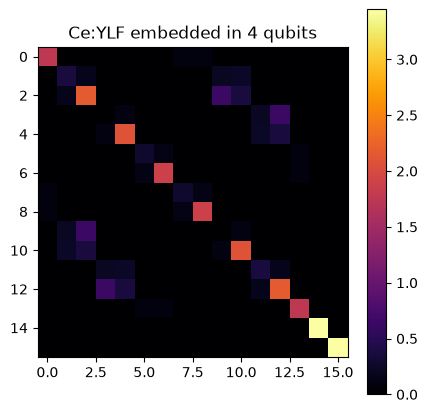

In [7]:
energy_unit = 1000.0
h, n_physical = crystal_field_hamiltonian(tensors, coeff, energy_unit=energy_unit)
h_matrix = h.backend.to_numpy(h.matrix)
print(f"nqubits = {h.nqubits}, physical states = {n_physical}, dimension = {2**h.nqubits}")
visualize_matrix(h_matrix, title="Ce:YLF embedded in 4 qubits")

In [8]:
energies, vectors = np.linalg.eigh(h_matrix)
print("max |E_embedded - E_PyCF| (cm^-1):", np.max(np.abs(energy_unit * energies[:n_physical] - energies_pycf)))
print("padding block coupling:", np.max(np.abs(h_matrix[:n_physical, n_physical:])))
print("padding energies (cm^-1):", energy_unit * energies[n_physical:], " highest physical:", energies_pycf[-1])

max |E_embedded - E_PyCF| (cm^-1): 5.9117155615240335e-12
padding block coupling: 0.0
padding energies (cm^-1): [3447.84526387 3447.84526387]  highest physical: 2658.571228394947


#### Eigenspaces

Ce$^{3+}$ has an odd number of electrons, so in zero field every level is an exact Kramers doublet. Individual eigenvectors inside a doublet are not unique, so we compare eigenspaces with the projector fidelity $F = \mathrm{Tr}(P_{\rm PyCF} P_{\rm Qibo})/d$.
Levels are grouped with an energy tolerance chosen from the exact spectrum: it must exceed the largest splitting inside a level and stay below the smallest gap between levels.

In [9]:
tol = 1e-5  # in energy_unit, i.e. 0.01 cm^-1
max_inside, min_between = check_grouping_tolerance(energies, tol)
print(f"largest splitting inside a level: {energy_unit*max_inside:.2e} cm^-1")
print(f"tolerance: {energy_unit*tol:.2e} cm^-1")
print(f"smallest gap between levels: {energy_unit*min_between:.2f} cm^-1")
groups = group_levels(energies, tol)
print("level degeneracies:", [len(g) for g in groups])

largest splitting inside a level: 2.66e-12 cm^-1
tolerance: 1.00e-02 cm^-1
smallest gap between levels: 96.59 cm^-1
level degeneracies: [2, 2, 2, 2, 2, 2, 2, 2]


In [10]:
vectors_pycf_embedded = np.zeros((2**h.nqubits, n_physical), dtype=complex)
vectors_pycf_embedded[:n_physical] = vectors_pycf
for k, g in enumerate(groups):
    if g[0] < n_physical:
        fidelity = subspace_fidelity(vectors_pycf_embedded[:, g], vectors[:, g])
        print(f"level {k}: E = {energy_unit*(energies[g[0]] - energies[0]):8.2f} cm^-1, d = {len(g)}, F = {fidelity:.12f}")

level 0: E =     0.00 cm^-1, d = 2, F = 1.000000000000
level 1: E =   212.32 cm^-1, d = 2, F = 1.000000000000
level 2: E =   412.92 cm^-1, d = 2, F = 1.000000000000
level 3: E =  2213.99 cm^-1, d = 2, F = 1.000000000000
level 4: E =  2310.58 cm^-1, d = 2, F = 1.000000000000
level 5: E =  2428.67 cm^-1, d = 2, F = 1.000000000000
level 6: E =  3157.10 cm^-1, d = 2, F = 1.000000000000


The embedded Hamiltonian reproduces the `PyCF` eigenvalues and eigenspaces to numerical precision, and the padding states are decoupled. The same conversion is used for the DBQA models.